# 03 - Model experiments (Week 2)

Churn, CLV and segmentation models for the Vantara customer platform.

* All models use the same stratified 70/15/15 split (seed 42). Hyperparameters were tuned with 5-fold CV on the training split only.
* Comparison and selection use the **validation** split. The **test** split was used once, at the end, for the two selected models.
* This notebook only reads saved results. It never trains models or touches the test split.

In [1]:
import json
from pathlib import Path

import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "docs").exists():
    ROOT = ROOT.parent
DOCS = ROOT / "docs"
pd.set_option("display.width", 140)

## 1. Churn models (validation split)

Selection rule (fixed before looking at the test split): highest validation ROC-AUC. Models within 0.005 AUC are treated as tied; the tie is broken by recall on recently active customers (recency <= 180 days), then precision.

In [2]:
churn = pd.read_csv(DOCS / "model_comparison.csv")
cols = ["model", "accuracy", "precision", "recall", "f1", "roc_auc", "search_seconds"]
churn[churn["subset"] == "all"].sort_values("roc_auc", ascending=False)[cols]

,model,accuracy,precision,recall,f1,roc_auc,search_seconds
6,xgboost,0.736,0.712,0.897,0.794,0.814,14.7
4,random_forest,0.749,0.787,0.762,0.774,0.813,37.0
8,lightgbm,0.752,0.753,0.834,0.791,0.807,13.0
0,logistic_regression,0.725,0.781,0.713,0.746,0.796,0.0
2,decision_tree,0.736,0.778,0.747,0.762,0.793,0.0
10,knn,0.730,0.742,0.800,0.770,0.782,0.8


### Recently active customers only (recency <= 180 days)

These customers are harder: they have bought recently, so churn is less obvious. Recall is lower than for all customers in every model.

In [3]:
churn[churn["subset"] != "all"].sort_values("recall", ascending=False)[cols[:6]]

,model,accuracy,precision,recall,f1,roc_auc
7,xgboost,0.702,0.584,0.716,0.643,0.785
9,lightgbm,0.731,0.657,0.594,0.624,0.779
11,knn,0.714,0.628,0.587,0.607,0.746
3,decision_tree,0.726,0.706,0.465,0.560,0.777
5,random_forest,0.741,0.767,0.445,0.563,0.780
1,logistic_regression,0.709,0.761,0.329,0.459,0.758


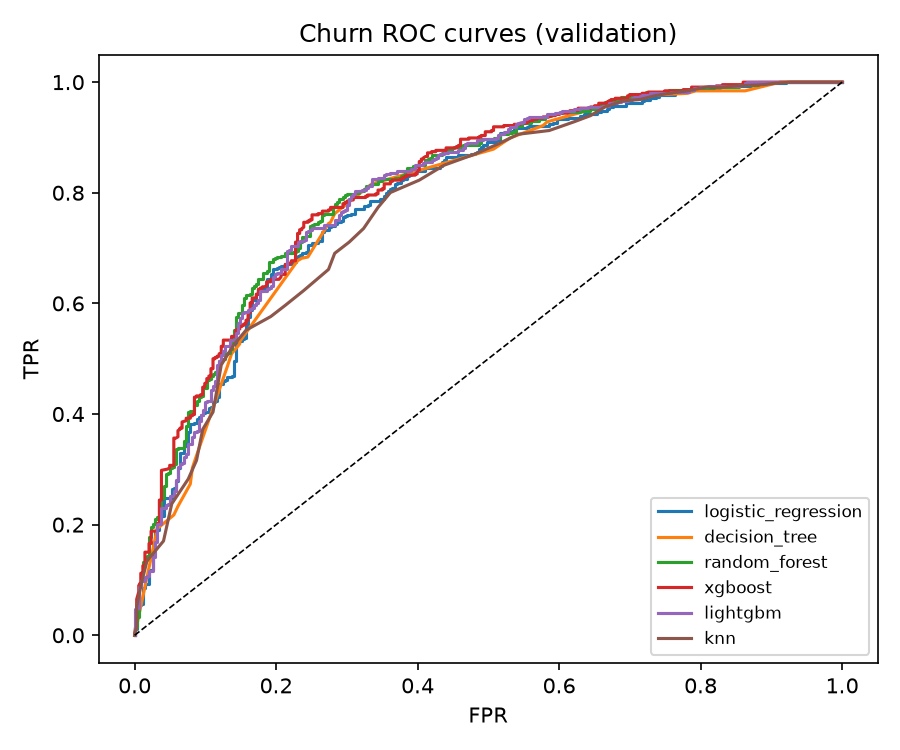

In [4]:
from IPython.display import Image

Image(filename=str(DOCS / "roc_validation.png"))

**Reading the table**

* The tree-based models (Random Forest, XGBoost, LightGBM) are close to each other in ROC-AUC; the differences are within noise, so the choice rests on the tie-break rule, not on a clear winner.
* The tuned ensembles beat the Logistic Regression baseline by only about 0.01 to 0.02 AUC. With about 5,000 customers and strong recency/frequency signals, a simple model already captures most of the signal.
* KNN, the distance-based comparison model, is behind the tree models, so their gain is not just an effect of feature scaling.
* `search_seconds` is the whole tuning time for tuned models and the plain fit time for Logistic Regression and Decision Tree, so it is not a like-for-like speed comparison. Compare the LightGBM and XGBoost rows for the speed difference.
* XGBoost uses the validation split for early stopping, so its validation score is slightly optimistic. The test split gives the unbiased number.

## 2. CLV models (validation split)

About 56% of customers have a CLV target of 0 (they do not buy again), so single regressors struggle. The two-stage model multiplies the churn model's P(active) by the expected spend of active customers.

Original scale = what the business sees. Log scale = ranking quality; the two-stage model is an expected value, so it scores poorly on the log scale by design.

In [5]:
clv = pd.read_csv(DOCS / "clv_comparison.csv")
clv[(clv["subset"] == "all")].sort_values(["scale", "r2"], ascending=[True, False])

,model,subset,scale,mae,rmse,r2
4,random_forest_reg,all,log,2.152,2.565,0.363
0,ridge,all,log,2.221,2.624,0.333
8,two_stage,all,log,3.072,3.671,-0.305
9,two_stage,all,original,438.141,1651.089,0.418
1,ridge,all,original,458.712,1777.085,0.326
5,random_forest_reg,all,original,446.536,1841.723,0.276


## 3. Segmentation

One-time buyers are split by a recency rule. Repeat customers are clustered with K-Means (k chosen by silhouette); a Gaussian Mixture Model was the second algorithm.

In [6]:
print(json.dumps(json.loads((DOCS / "segmentation_summary.json").read_text()), indent=2))
pd.read_csv(DOCS / "segment_profiles.csv", index_col=0)

{
  "one_time_buyers": 1575,
  "repeat_customers": 3681,
  "kmeans": {
    "k": 3,
    "silhouette": 0.3382,
    "davies_bouldin": 0.9897
  },
  "gmm": {
    "components": 8,
    "silhouette": 0.0348,
    "davies_bouldin": 2.6244
  },
  "agreement_adjusted_rand_index": 0.2028
}


,customers,share,recency_days,frequency,monetary_total,monetary_avg,return_rate,seasonal_concentration,churn_rate,mean_clv_target
segment_name,,,,,,,,,,
Lapsed low-value,2154,0.410,196.0,3.0,738.74,233.96,0.00,0.50,0.614,216.3
Loyal high-value,1485,0.283,36.0,10.0,3494.10,364.87,0.00,0.19,0.247,1457.1
One-time buyer (lapsed),1179,0.224,372.0,1.0,228.96,228.96,0.00,1.00,0.847,73.1
One-time buyer (recent),396,0.075,81.0,1.0,241.92,241.92,0.00,1.00,0.639,201.4
High-return buyer,42,0.008,177.5,4.0,930.34,248.74,0.45,0.58,0.643,298.2


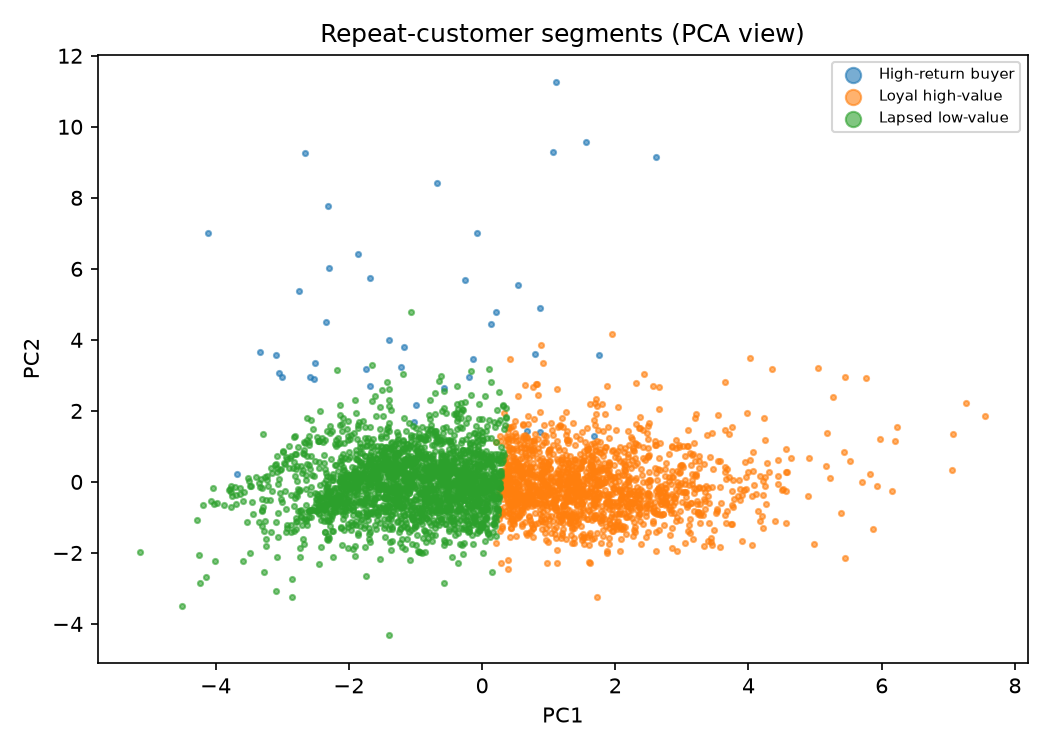

In [7]:
Image(filename=str(DOCS / "segments_pca.png"))

* K-Means gave a clearer structure (silhouette about 0.34) than the GMM, whose BIC kept falling up to the largest size tried and whose silhouette was close to zero.
* The small high-return segment is named for its return rate. No clearly seasonal segment was found in this data.

## 4. Final test-set evaluation (used once)

Only the selected churn model and the selected CLV model were scored on the test split. Targets from the PRD: churn ROC-AUC >= 0.80, churn recall >= 0.70, CLV R-squared >= 0.60.

In [8]:
results = json.loads((DOCS / "test_results.json").read_text())
print("churn model:", results["churn_model"], "| clv model:", results["clv_model"])
pd.DataFrame(results["churn_test"]).T

churn model: xgboost | clv model: two_stage


,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
all,0.7490,0.7214,0.9058,0.8032,0.8039,187.0,156.0,42.0,404.0
recency<=180,0.7253,0.6166,0.7484,0.6761,0.8022,182.0,74.0,40.0,119.0


In [9]:
pd.DataFrame(results["clv_test"]).T

,mae,rmse,r2
all|log,3.0971,3.6981,-0.3133
all|original,690.4230,5765.6421,0.1338
recency<=180|log,2.4845,3.3167,-0.0206
recency<=180|original,1141.9349,7942.0032,0.1252


In [10]:
pd.Series(results["targets_met"], name="target met")

churn_roc_auc >= 0.80       True
churn_recall >= 0.70        True
clv_r2_original >= 0.60    False
Name: target met, dtype: bool

## 5. Limitations

* One cutoff date (2011-09-10) and one 90-day window; the models are not tested across different time periods.
* Recall for recently active customers is much lower than the overall recall.
* The CLV R-squared target of 0.60 was not reached on the validation split; see section 4 for the test result. The reasons to report: many zero-spend customers and a few very large ones.
* The next-purchase-category target exists in the data but is not modeled in this project.